In [ ]:
import random, numpy as np, torch, transformers
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, "| transformers", transformers.__version__)

cuda | transformers 5.18.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive/notebook/data -name "*.png" | wc -l
!find /content/drive/MyDrive/notebook/data -name "*.png" | head -3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
128
/content/drive/MyDrive/notebook/data/emb_pca_tsne.png
/content/drive/MyDrive/notebook/data/probe_confusion.png
/content/drive/MyDrive/notebook/data/probe_errors.png


config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.2k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

/content/drive/MyDrive/notebook/data/Figures_ESEM2022/3544902.3546233_p5_fig1.png
torch.Size([1, 768])


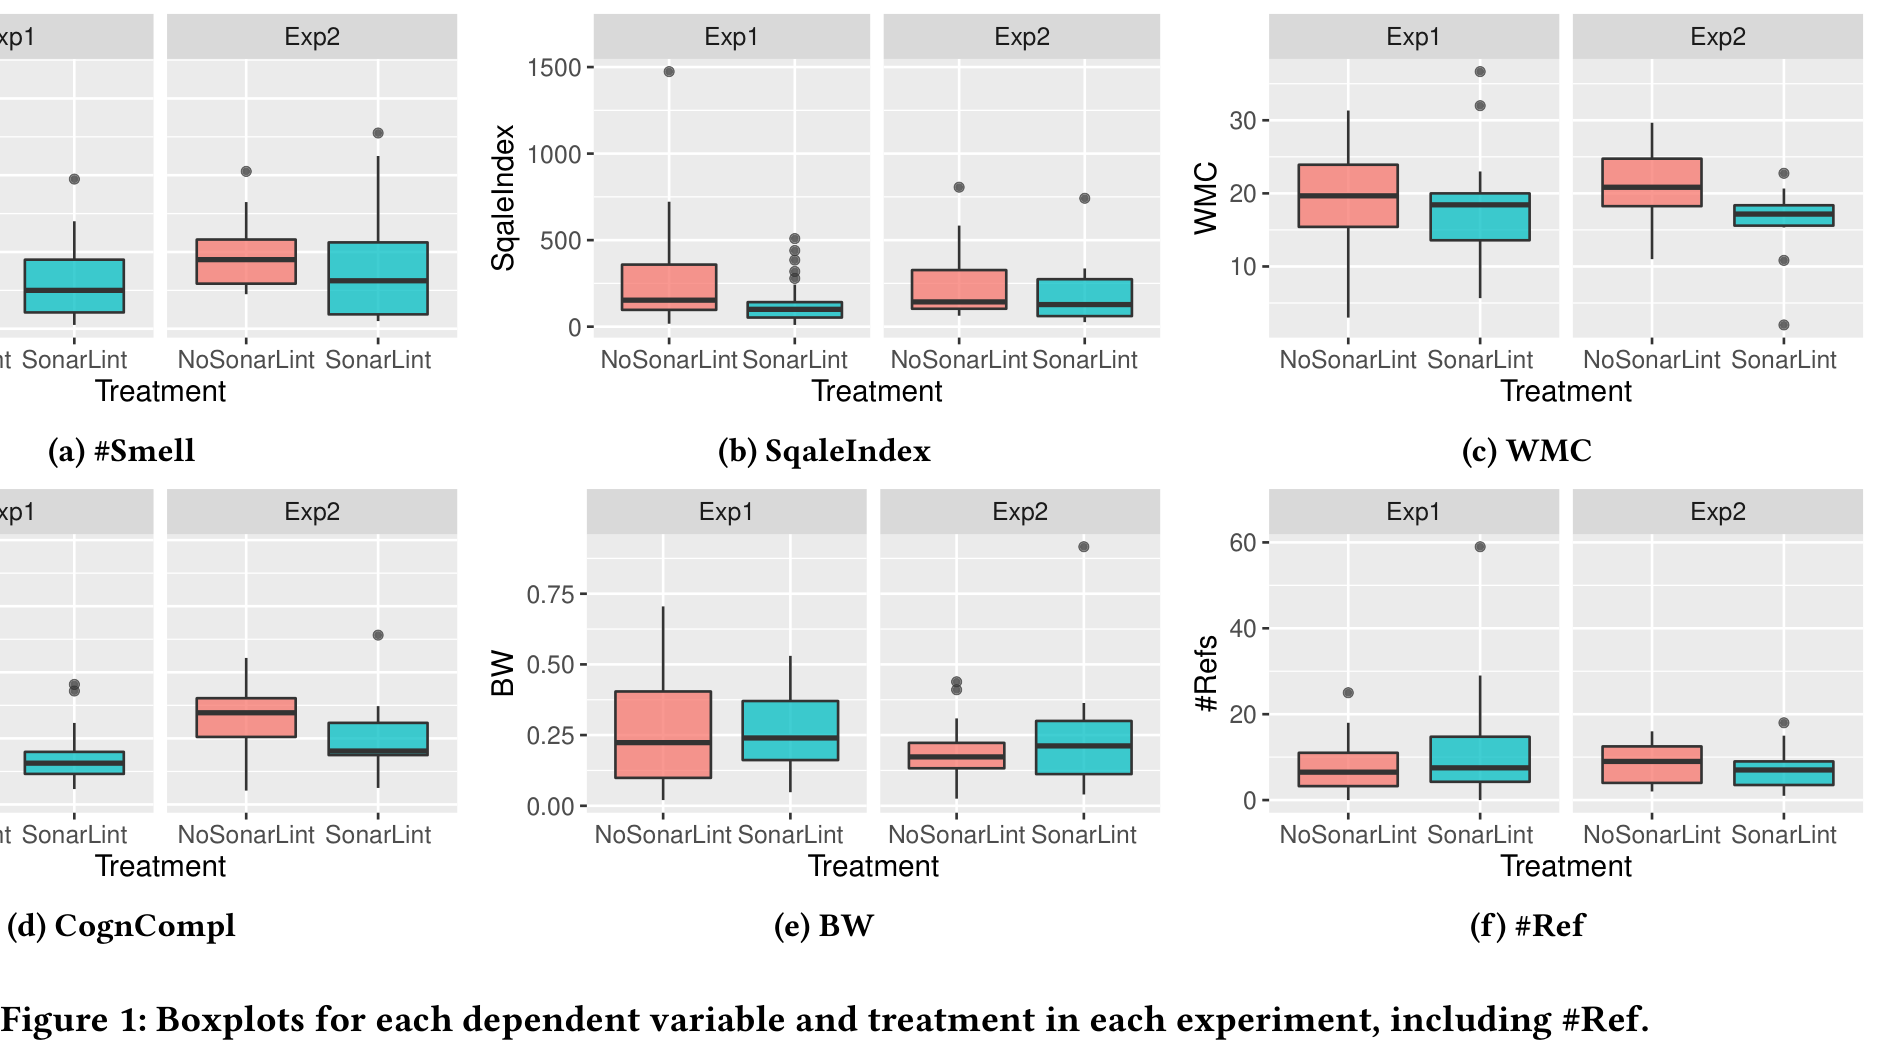

In [ ]:
from transformers import AutoModel, AutoProcessor
from PIL import Image
import glob

MODEL_ID = "google/siglip2-base-patch16-224"
model = AutoModel.from_pretrained(MODEL_ID).to(device).eval()
processor = AutoProcessor.from_pretrained(MODEL_ID)

path = sorted(glob.glob("/content/drive/MyDrive/notebook/data/Figures_ESEM2022/*.png", recursive=True))[0]
img = Image.open(path).convert("RGB")

inputs = processor(images=img, return_tensors="pt").to(device)
with torch.no_grad():
    emb = model.get_image_features(**inputs)
if not torch.is_tensor(emb):        # newer library versions wrap the result
    emb = emb.pooler_output

print(path)
print(emb.shape)
img                                  # last line of a cell gets displayed

In [ ]:
import pandas as pd, os, io
from google.colab import files

DATA = "/content/drive/MyDrive/notebook/data"
IMG_DIR = f"{DATA}/Figures_ESEM2022"

up = files.upload()                                   # pick labels_cleaned.csv
df = pd.read_csv(io.BytesIO(next(iter(up.values()))),
                 sep=";",          # values separated by ;
                 skiprows=1)       # skip the 'labels2' title line
df.columns = df.columns.str.strip()

df.to_csv(f"{DATA}/labels_clean.csv", index=False)   # save a normal comma version to Drive

df = df[df.Image != "3544902.3546233_p7_fig3.png"]                       # bad crop
df = df.drop_duplicates(subset="Image")                                  # safety
df = df[df.Image.apply(lambda f: os.path.exists(f"{IMG_DIR}/{f}"))].reset_index(drop=True)
print(df.columns.tolist())
print(len(df), df.Label.value_counts().to_dict())

Saving labels_cleaned.csv to labels_cleaned (1).csv
['Image', 'Paper', 'Fig', 'Type', 'Label']
122 {'Q': 68, 'NonQ': 54}


In [ ]:
embs = []
for i in range(0, len(df), 16):                       # batches of 16
    imgs = [Image.open(f"{IMG_DIR}/{f}").convert("RGB") for f in df.Image[i:i+16]]
    inputs = processor(images=imgs, return_tensors="pt").to(device)
    with torch.no_grad():
        e = model.get_image_features(**inputs)
    if not torch.is_tensor(e): e = e.pooler_output
    embs.append(e.cpu().numpy())

X = np.concatenate(embs)                  # shape (n_images, 768)
y = (df.Label == "Q").astype(int).values  # 1 = Q, 0 = NonQ
np.save(f"{DATA}/emb_siglip2_base.npy", X)
df.to_csv(f"{DATA}/emb_siglip2_base_index.csv", index=False)   # row order of X
print(X.shape, "share of Q:", y.mean().round(2))

(122, 768) share of Q: 0.56


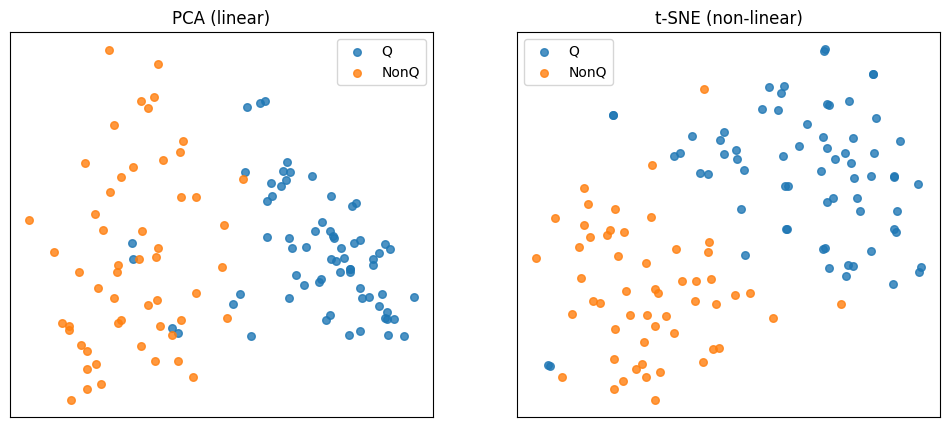

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xn = X / np.linalg.norm(X, axis=1, keepdims=True)    # scale every vector to length 1
pca  = PCA(n_components=2, random_state=SEED).fit_transform(Xn)
tsne = TSNE(n_components=2, perplexity=20, init="pca", random_state=SEED).fit_transform(Xn)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, Z, title in [(axes[0], pca, "PCA (linear)"), (axes[1], tsne, "t-SNE (non-linear)")]:
    for lab, color in [("Q", "tab:blue"), ("NonQ", "tab:orange")]:
        m = (df.Label == lab).values
        ax.scatter(Z[m, 0], Z[m, 1], c=color, label=lab, s=30, alpha=0.8)
    ax.set_title(title); ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.savefig(f"{DATA}/emb_pca_tsne.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score

groups = df.Paper.values
probe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))

grouped = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
naive   = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# show what each grouped test fold contains
for k, (tr, te) in enumerate(grouped.split(Xn, y, groups)):
    print(f"fold {k}: {len(te)} images, {len(set(groups[te]))} papers, Q share {y[te].mean():.2f}")

pred_grouped = cross_val_predict(probe, Xn, y, cv=grouped, groups=groups)
pred_naive   = cross_val_predict(probe, Xn, y, cv=naive)

print("\ngrouped CV (honest):", round(accuracy_score(y, pred_grouped), 3))
print("naive CV (leaky):   ", round(accuracy_score(y, pred_naive), 3))
print("always-Q baseline:  ", round(y.mean(), 3))

df["pred_probe"] = pred_grouped     # keep for the McNemar test later

fold 0: 20 images, 4 papers, Q share 0.20
fold 1: 23 images, 5 papers, Q share 0.61
fold 2: 30 images, 5 papers, Q share 0.83
fold 3: 18 images, 4 papers, Q share 0.33
fold 4: 31 images, 5 papers, Q share 0.61

grouped CV (honest): 0.943
naive CV (leaky):    0.975
always-Q baseline:   0.557


In [ ]:
print(set(pd.read_csv(f"{DATA}/labels_clean.csv").Image) - set(os.listdir(IMG_DIR)))

{'3544902.3546233_p7_fig3.png'}


grouped: 115/122 = 0.943  95% CI [0.886, 0.972]
naive:   119/122 = 0.975  95% CI [0.930, 0.992]
balanced accuracy: 0.947
ROC-AUC:           0.987
              precision    recall  f1-score   support

        NonQ      0.898     0.981     0.938        54
           Q      0.984     0.912     0.947        68

    accuracy                          0.943       122
   macro avg      0.941     0.947     0.942       122
weighted avg      0.946     0.943     0.943       122



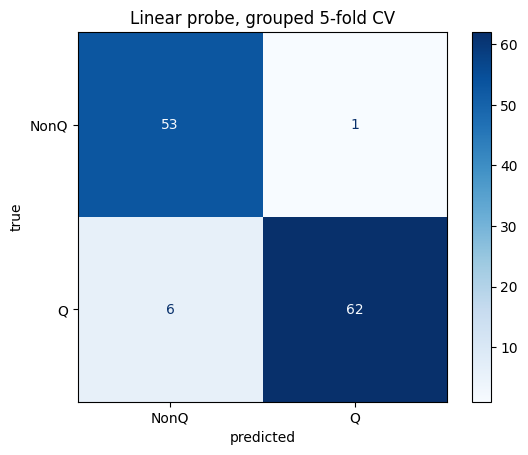

grouped, 10 splits: mean 0.947  sd 0.010
naive,   10 splits: mean 0.989  sd 0.011


In [ ]:
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             balanced_accuracy_score, roc_auc_score)

# probabilities instead of hard 0/1 answers (same folds as before -> same predictions)
proba = cross_val_predict(probe, Xn, y, cv=grouped, groups=groups, method="predict_proba")[:, 1]
pred  = (proba >= 0.5).astype(int)

def wilson(pred, y):
    k, n = int((pred == y).sum()), len(y)
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return f"{k}/{n} = {k/n:.3f}  95% CI [{lo:.3f}, {hi:.3f}]"

print("grouped:", wilson(pred, y))
print("naive:  ", wilson(pred_naive, y))
print("balanced accuracy:", round(balanced_accuracy_score(y, pred), 3))
print("ROC-AUC:          ", round(roc_auc_score(y, proba), 3))
print(classification_report(y, pred, target_names=["NonQ", "Q"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["NonQ", "Q"]).plot(cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Linear probe, grouped 5-fold CV")
plt.savefig(f"{DATA}/probe_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

# repeat both CVs with 10 different random splits -> is the naive>grouped gap consistent?
acc_g, acc_n = [], []
for s in range(10):
    g = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
    nv = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
    acc_g.append(accuracy_score(y, cross_val_predict(probe, Xn, y, cv=g, groups=groups)))
    acc_n.append(accuracy_score(y, cross_val_predict(probe, Xn, y, cv=nv)))
print(f"grouped, 10 splits: mean {np.mean(acc_g):.3f}  sd {np.std(acc_g):.3f}")
print(f"naive,   10 splits: mean {np.mean(acc_n):.3f}  sd {np.std(acc_n):.3f}")

7 misclassified



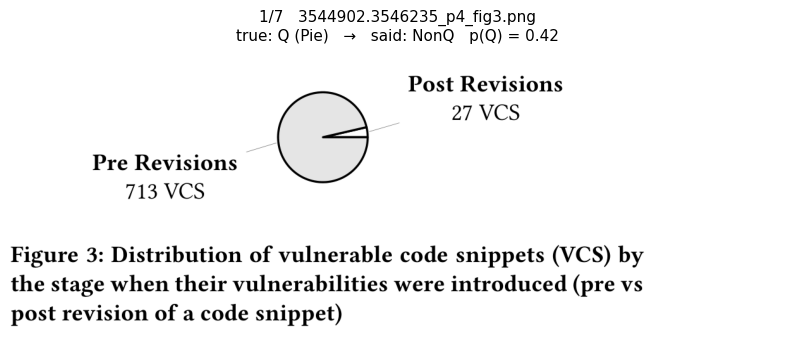

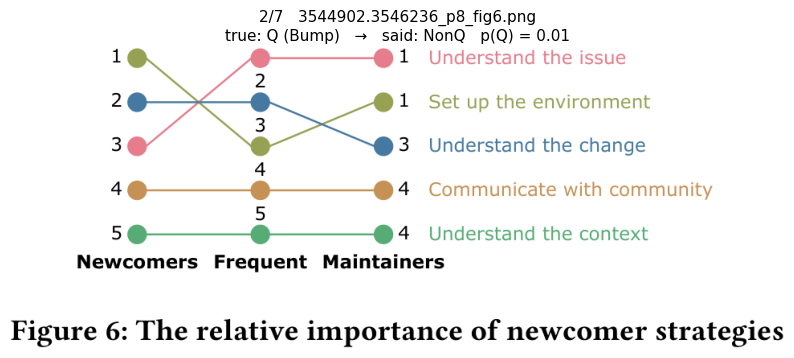

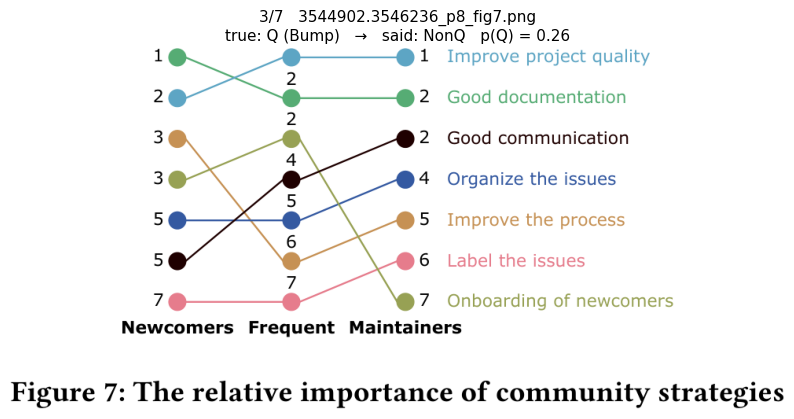

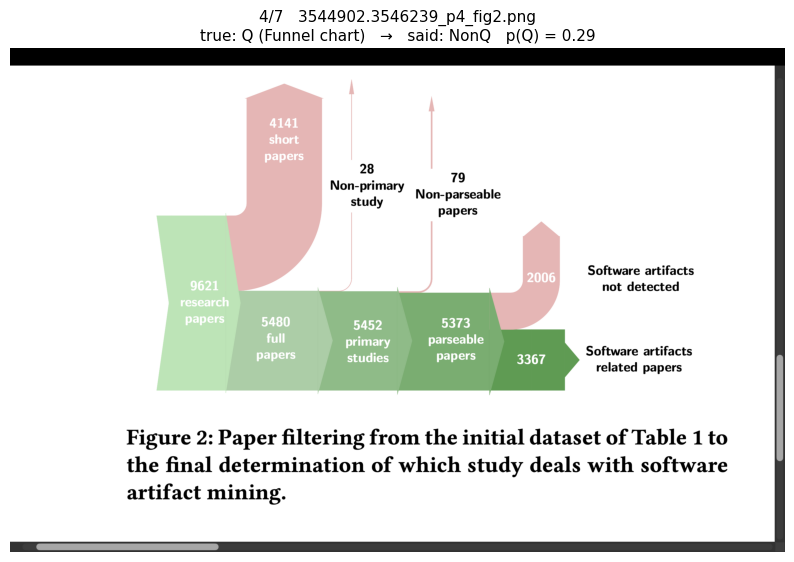

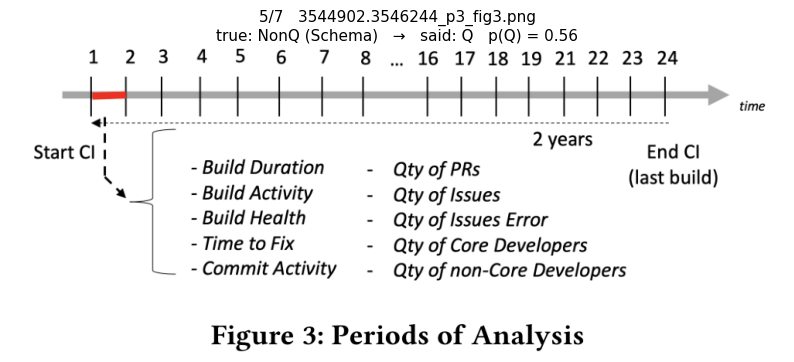

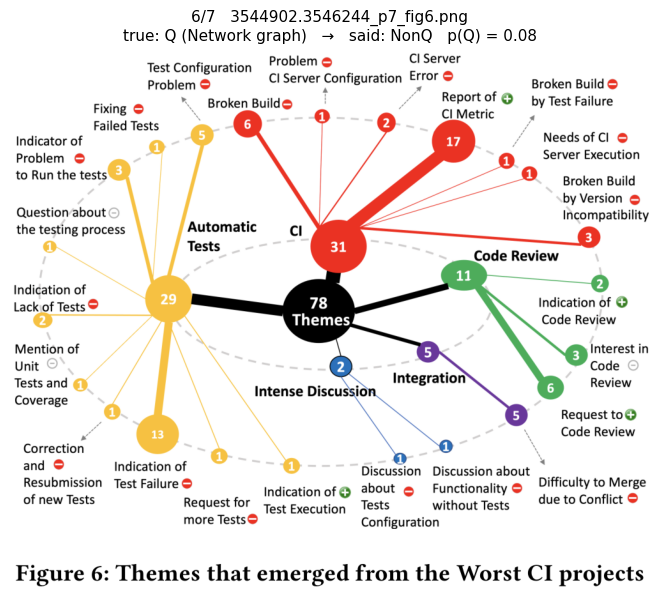

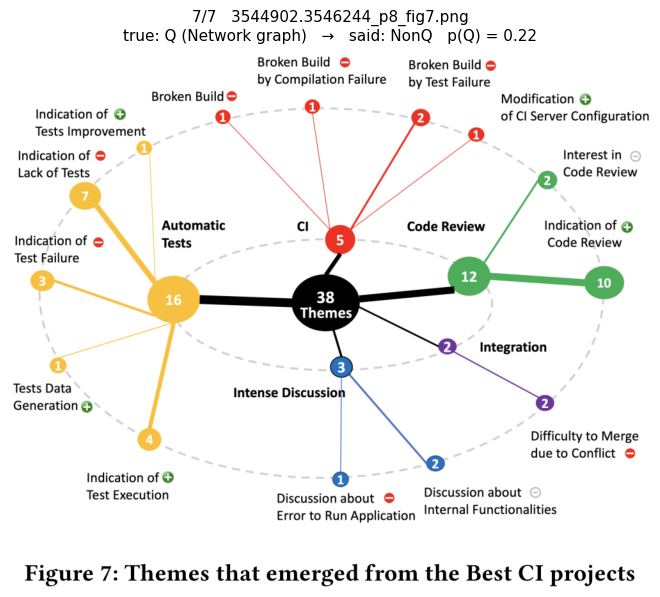

In [ ]:
wrong = np.where(pred != y)[0]
print(len(wrong), "misclassified\n")

for n, i in enumerate(wrong, 1):
    img = Image.open(f"{IMG_DIR}/{df.Image[i]}").convert("RGB")
    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{n}/{len(wrong)}   {df.Image[i]}\n"
              f"true: {df.Label[i]} ({df.Type[i]})   →   said: {'Q' if pred[i] else 'NonQ'}   p(Q) = {proba[i]:.2f}",
              fontsize=11)
    plt.show()

train size  10: 0.866 ± 0.043
train size  20: 0.916 ± 0.019
train size  40: 0.927 ± 0.019
train size  75: 0.941 ± 0.016
train size  97: 0.944 ± 0.011


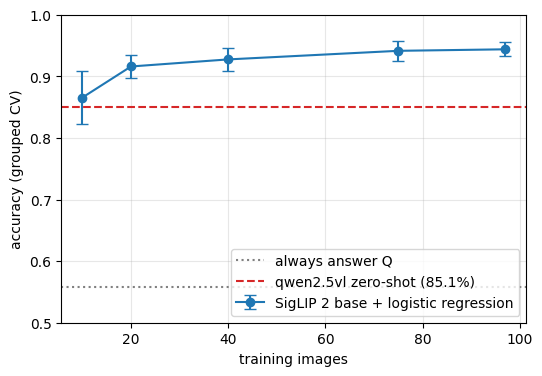

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

sizes = [10, 20, 40, 75, None]            # None = use the whole training fold
curve = {s: [] for s in sizes}
for rep in range(20):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=rep)
    correct = {s: 0 for s in sizes}
    for tr, te in cv.split(Xn, y, groups):
        for s in sizes:
            if s is None or s >= len(tr) - 2:   # safety: never leave < 2 images over
                sub = tr
            else:
                sub, _ = train_test_split(tr, train_size=s, stratify=y[tr], random_state=rep)
            m = clone(probe).fit(Xn[sub], y[sub])
            correct[s] += (m.predict(Xn[te]) == y[te]).sum()
    for s in sizes:
        curve[s].append(correct[s] / len(y))

full_n = int(len(y) * 4 / 5)              # average training-fold size (~88)
xs   = [s if s else full_n for s in sizes]
mean = [np.mean(curve[s]) for s in sizes]
sd   = [np.std(curve[s]) for s in sizes]
for x, m_, s_ in zip(xs, mean, sd):
    print(f"train size {x:3d}: {m_:.3f} ± {s_:.3f}")

plt.figure(figsize=(6, 4))
plt.errorbar(xs, mean, yerr=sd, marker="o", capsize=4, label="SigLIP 2 base + logistic regression")
plt.axhline(y.mean(), ls=":", c="gray", label="always answer Q")
plt.axhline(0.851, ls="--", c="tab:red", label="qwen2.5vl zero-shot (85.1%)")
plt.xlabel("training images"); plt.ylabel("accuracy (grouped CV)")
plt.ylim(0.5, 1); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig(f"{DATA}/learning_curve.png", dpi=200, bbox_inches="tight"); plt.show()